In [18]:
import pandas as pd
import numpy as np

# Read the CSV file into a pandas DataFrame
#df = pd.read_csv('/Users/visjostr/school/parking-prediction/parking-data/Turkuparkkihub_parkings_anon.csv', delimiter=';')
df = pd.read_csv('../data/Turkuparkkihub_parkings_anon.csv', delimiter=';')


# Assuming df is your DataFrame
df['created_at'] = pd.to_datetime(df['created_at'], format='%d/%m/%Y %H.%M')

df['date'] = df['created_at'].dt.date
number_of_cars_per_day = df.groupby('date').size()

df['day_of_year'] = df['created_at'].dt.dayofyear

df['weekday'] = df['created_at'].dt.weekday + 1  # Adding 1 to make Monday=1, Sunday=7

df['hour'] = df['created_at'].dt.hour
df_charging_hours = df[(df['hour'] >= 9) & (df['hour'] < 18)]


holidays = ['2021-11-04','2021-12-06','2021-12-25', '2022-01-01','2022-01-06']  # Holiday dates for the time period of the dataset
holidays = pd.to_datetime(holidays).date

df['is_holiday'] = np.where((df['weekday'] == 7) | (df['date'].isin(holidays)), 1, 0)


In [19]:
# Aggregate number of cars per day during charging hours
number_of_cars_per_day_charging_hours = df_charging_hours.groupby('date').size()

# Create final DataFrame
features_df = pd.DataFrame({
    'number_of_cars_per_day': number_of_cars_per_day,
    'day_of_year': df.groupby('date')['day_of_year'].first(),
    'weekday': df.groupby('date')['weekday'].first(),
    'is_holiday': df.groupby('date')['is_holiday'].first()
})

# Fill NaNs with 0 where applicable (e.g., days with no cars in charging hours)
features_df.fillna(0, inplace=True)

print(features_df)


            number_of_cars_per_day  day_of_year  weekday  is_holiday
date                                                                
2021-08-10                       4          222        2           0
2021-08-11                       3          223        3           0
2021-08-12                       1          224        4           0
2021-08-13                       8          225        5           0
2021-08-14                       2          226        6           0
...                            ...          ...      ...         ...
2022-01-13                    5412           13        4           0
2022-01-14                    6341           14        5           0
2022-01-15                    3242           15        6           0
2022-01-16                     331           16        7           1
2022-01-17                    1264           17        1           0

[160 rows x 4 columns]


                                 SARIMAX Results                                  
Dep. Variable:     number_of_cars_per_day   No. Observations:                  160
Model:                     ARIMA(3, 1, 2)   Log Likelihood               -1416.726
Date:                    Mon, 27 May 2024   AIC                           2845.453
Time:                            16:12:02   BIC                           2863.866
Sample:                                 0   HQIC                          2852.930
                                    - 160                                         
Covariance Type:                      opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4078      0.093     -4.406      0.000      -0.589      -0.226
ar.L2          0.0484      0.095      0.510      0.610      -0.138       0.234
ar.L3         -0.230

c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary sta

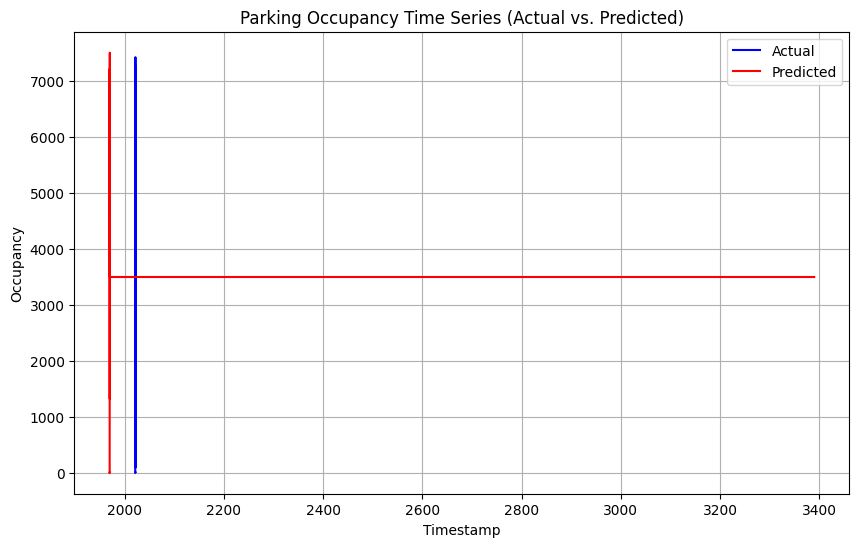

In [20]:
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt

# Define ARIMA model parameters (p, d, q)
p = 3  # Autoregressive (AR) order
d = 1  # Integrated (I) order (degree of differencing)
q = 2  # Moving Average (MA) order

# Example: fitting ARIMA on number of cars per day 
model = ARIMA(features_df['number_of_cars_per_day'], order=(p, d, q))
arima_results = model.fit()
print(arima_results.summary())


# Generate predictions
predictions = arima_results.predict(start=df.index[0], end=df.index[-1])

# Plot actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.plot(features_df.index, features_df['number_of_cars_per_day'], color='blue', label='Actual')
plt.plot(predictions.index, predictions, color='red', label='Predicted')
plt.title('Parking Occupancy Time Series (Actual vs. Predicted)')
plt.xlabel('Timestamp')
plt.ylabel('Occupancy')
plt.legend()
plt.grid(True)
plt.show()
